# Text Features for Churn Prediction: A Beginner's Guide
This notebook builds a small fake customer base, turns each customer's support ticket into a sentiment score and a topic label, and checks whether those text features help a simple churn model on customers it has never seen. It also shows the trap: adding lots of raw word columns makes the training score look great while the test score gets worse.

## Step 0: the tools
I only use numpy, pandas and matplotlib, plus `re` from the standard library for splitting text into words. The logistic regression is a small numpy version, so you can see every moving part.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

## Step 1: make up some customers
**All data here is simulated.** I create 2,000 customers with three usage columns: logins last month, seat count and whether they are on the annual plan.

Each customer also gets a hidden "mood", meaning how unhappy they really are. The model never sees this column. Unhappy customers churn more often, and they also write grumpier tickets about bugs and billing. That is the whole point: the mood only reaches the model through the text.

In [2]:
n = 2000
logins = rng.poisson(12, n)
seats = rng.integers(1, 30, n)
annual = (rng.random(n) < 0.4).astype(int)
mood = rng.normal(0, 1, n)  # hidden unhappiness, never given to the model

logit = -1.2 - 0.08 * (logins - 12) - 0.6 * annual - 0.02 * (seats - 15) + 1.3 * mood
churn = (rng.random(n) < 1 / (1 + np.exp(-logit))).astype(int)

print(f"Customers: {n}")
print(f"Churn rate: {churn.mean():.1%}")

Customers: 2000
Churn rate: 25.4%


## Step 2: give every customer one support ticket
Each ticket is glued together from three parts: a tone phrase (friendly, neutral or curt), a sentence about the topic, and a sign-off line with a city and a weekday.

Unhappy customers are more likely to write about bugs and billing and less likely to send praise. The city and weekday are pure noise. They have nothing to do with churn, which will matter later.

In [3]:
topics = ["billing", "bug", "missing feature", "how to", "praise"]
topic_sentences = {
    "billing": ["The invoice amount looks wrong.", "Can I get a refund for last month?", "Why was my card charged twice?"],
    "bug": ["The export is still broken.", "The dashboard will not load.", "Sync fails with an error."],
    "missing feature": ["We really need scheduled reports.", "I wish there was an API.", "Please add dark mode."],
    "how to": ["How do I add a user?", "Where do I change my password?", "How do I invite my team?"],
    "praise": ["Love the new dashboard.", "Great support on my last ticket.", "The update works great."],
}
tone_phrases = {
    "negative": ["Third time asking.", "This is unacceptable.", "Very frustrated right now."],
    "neutral": ["Hi team.", "Quick question.", "Hello."],
    "positive": ["Hope you are well!", "Happy with things so far.", "Thanks in advance!"],
}
cities = ["Austin", "Berlin", "Lyon", "Oslo", "Porto", "Quito", "Lagos", "Perth", "Turin", "Kyoto",
          "Dublin", "Leeds", "Malmo", "Graz", "Bern", "Cork", "Riga", "Split", "Bergen", "Ghent"]
weekdays = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

tickets, true_topics = [], []
for m in mood:
    weights = np.array([np.exp(0.6 * m), np.exp(0.9 * m), np.exp(0.3 * m), 1.0, np.exp(-1.0 * m)])
    topic = rng.choice(topics, p=weights / weights.sum())
    tone_level = m + rng.normal(0, 0.7)
    tone = "negative" if tone_level > 0.6 else "positive" if tone_level < -0.6 else "neutral"
    text = (f"{rng.choice(tone_phrases[tone])} {rng.choice(topic_sentences[topic])} "
            f"Sent from {rng.choice(cities)} on {rng.choice(weekdays)}.")
    tickets.append(text)
    true_topics.append(topic)

df = pd.DataFrame({"logins": logins, "seats": seats, "annual": annual,
                   "ticket": tickets, "churn": churn})
for t in df["ticket"].head(4):
    print(t)

Hello. The update works great. Sent from Lyon on Wednesday.
Hello. I wish there was an API. Sent from Malmo on Wednesday.
Third time asking. Great support on my last ticket. Sent from Leeds on Friday.
Hello. Where do I change my password? Sent from Austin on Thursday.


## Step 3: turn the text into two numbers
Now the part the post is about. The model can't read sentences, so I turn each ticket into features with two very simple rules.

* **Sentiment score:** count happy words and grumpy words from a short list. The score is (happy minus grumpy) divided by (happy plus grumpy), so it runs from minus one to plus one. No such words means zero.
* **Topic label:** a keyword rule. "Invoice" or "refund" means billing, "broken" or "error" means bug, and so on. Anything that matches nothing becomes "how to".

Notice the model never gets the true topic I used to generate the ticket. It only gets what the keyword rule reads from the text, which is what you would have in real life.

In [4]:
positive_words = {"love", "great", "thanks", "happy", "well", "works"}
negative_words = {"broken", "fails", "error", "wrong", "frustrated", "unacceptable", "still", "third", "twice"}
topic_keywords = [
    ("billing", {"invoice", "refund", "charged", "card"}),
    ("bug", {"broken", "load", "error", "fails"}),
    ("missing feature", {"need", "wish", "please"}),
    ("praise", {"love", "great"}),
]

def tokenize(text):
    return re.findall(r"[a-z]+", text.lower())

def sentiment_score(text):
    words = tokenize(text)
    pos = sum(w in positive_words for w in words)
    neg = sum(w in negative_words for w in words)
    return 0.0 if pos + neg == 0 else (pos - neg) / (pos + neg)

def topic_label(text):
    words = set(tokenize(text))
    for label, keys in topic_keywords:
        if words & keys:
            return label
    return "how to"

df["sentiment"] = df["ticket"].apply(sentiment_score)
df["topic"] = df["ticket"].apply(topic_label)

print(f"Keyword rule agrees with the true topic for {np.mean(df['topic'] == np.array(true_topics)):.1%} of tickets\n")
for _, row in df.head(4).iterrows():
    print(f"{row['sentiment']:+.2f}  {row['topic']:<16} {row['ticket']}")

Keyword rule agrees with the true topic for 100.0% of tickets

+1.00  praise           Hello. The update works great. Sent from Lyon on Wednesday.
+0.00  missing feature  Hello. I wish there was an API. Sent from Malmo on Wednesday.
+0.00  praise           Third time asking. Great support on my last ticket. Sent from Leeds on Friday.
+0.00  how to           Hello. Where do I change my password? Sent from Austin on Thursday.


## Step 4: a tiny logistic regression and AUC, in numpy
Logistic regression takes a weighted sum of the columns and squashes it into a probability between 0 and 1. Training means nudging the weights, step by step, so the probabilities get closer to who actually churned. That nudging is called gradient descent.

AUC is the score from the post: pick one churner and one customer who stayed at random, and AUC is the chance the model ranked the churner as riskier. 0.5 is a coin flip, 1.0 is perfect.

I also scale every column using the training customers only, so no column wins just because its numbers are bigger.

In [5]:
def fit_logreg(X, y, lr=0.5, steps=2000):
    Xb = np.c_[np.ones(len(X)), X]
    w = np.zeros(Xb.shape[1])
    for _ in range(steps):
        p = 1 / (1 + np.exp(-np.clip(Xb @ w, -30, 30)))
        w -= lr * Xb.T @ (p - y) / len(y)
    return w

def predict(w, X):
    return 1 / (1 + np.exp(-np.clip(np.c_[np.ones(len(X)), X] @ w, -30, 30)))

def auc(y, scores):
    ranks = pd.Series(scores).rank().to_numpy()
    n_pos, n_neg = y.sum(), len(y) - y.sum()
    return (ranks[y == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)

def scale(train, test):
    mu, sd = train.mean(axis=0), train.std(axis=0)
    sd[sd == 0] = 1
    return (train - mu) / sd, (test - mu) / sd

## Step 5: hold some customers back, then build two models
I shuffle the customers and split them in half. The model learns from the **training set** and gets graded on the **test set**, which it never sees while learning. Think of it as the new exam.

Then I build two models with the same algorithm, the same split and the same settings:

* **Baseline:** logins, seats, annual plan.
* **With text:** the same three columns plus the sentiment score and one yes/no column for each topic ("how to" is the default, so it needs no column).

In this simulation every ticket is written before we make the prediction, so there is no leakage. With real data you would have to throw out tickets written after the prediction date, like the cancellation email itself.

In [6]:
order = rng.permutation(n)
train_idx, test_idx = order[: n // 2], order[n // 2:]
y_train, y_test = df["churn"].to_numpy()[train_idx], df["churn"].to_numpy()[test_idx]

usage_cols = ["logins", "seats", "annual"]
topic_dummies = pd.get_dummies(df["topic"]).drop(columns="how to").astype(float)
X_base = df[usage_cols].to_numpy(float)
X_text = np.c_[X_base, df["sentiment"].to_numpy(), topic_dummies.to_numpy()]

results = {}
for name, X in [("Baseline (usage only)", X_base), ("With text features", X_text)]:
    Xtr, Xte = scale(X[train_idx], X[test_idx])
    w = fit_logreg(Xtr, y_train)
    results[name] = (auc(y_train, predict(w, Xtr)), auc(y_test, predict(w, Xte)))
    print(f"{name:<24} train AUC {results[name][0]:.3f}   test AUC {results[name][1]:.3f}")

improvement = results["With text features"][1] - results["Baseline (usage only)"][1]
print(f"\nImprovement on held-out customers: {improvement:+.3f} AUC")

Baseline (usage only)    train AUC 0.578   test AUC 0.559


With text features       train AUC 0.771   test AUC 0.705

Improvement on held-out customers: +0.146 AUC


## Chart 1: did the text help on new customers?
This is the one comparison the post keeps coming back to: test AUC with text minus test AUC without it. Here the text features clearly win. That makes sense, because the hidden mood only shows up in the tickets.

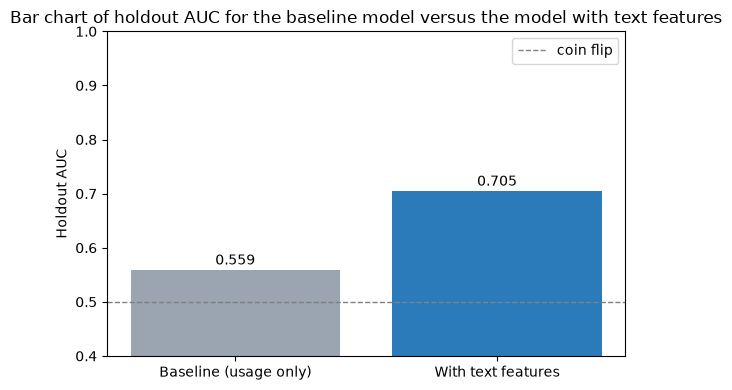

In [7]:
names = list(results)
test_aucs = [results[k][1] for k in names]
plt.figure(figsize=(6, 4))
bars = plt.bar(names, test_aucs, color=["#9aa5b1", "#2b7bba"])
for b, v in zip(bars, test_aucs):
    plt.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.3f}", ha="center")
plt.axhline(0.5, color="grey", linestyle="--", linewidth=1, label="coin flip")
plt.ylim(0.4, 1.0)
plt.ylabel("Holdout AUC")
plt.legend()
plt.title("Bar chart of holdout AUC for the baseline model versus the model with text features")
plt.tight_layout()
plt.show()

## Step 6: the trap of adding every word as a column
Now the temptation from the post: why stop at a sentiment score and a topic? Let's add one yes/no column for every word in the tickets ("bag of words").

To make the effect easy to see, I train on only 200 of the training customers, which is closer to how few churners many teams really have. I start from the text model above and add word columns in batches, from the most common words to the rarest. Many of these words are city names and weekdays, which I know are pure noise.

For each size I record the AUC on the training customers and on the full test set. The test set is still 1,000 customers the model never saw.

In [8]:
small_idx = train_idx[:200]
y_small = df["churn"].to_numpy()[small_idx]

token_sets = df["ticket"].apply(lambda t: set(tokenize(t)))
counts = pd.Series([w for s in token_sets.iloc[small_idx] for w in s]).value_counts()
vocab = sorted(counts.index, key=lambda w: (-counts[w], w))
word_matrix = np.array([[w in s for w in vocab] for s in token_sets], dtype=float)
print(f"Vocabulary size in the small training set: {len(vocab)} words")

sizes = [0, 5, 10, 20, 40, 60, 80, len(vocab)]
train_scores, test_scores = [], []
for k in sizes:
    X = np.c_[X_text, word_matrix[:, :k]]
    Xtr, Xte = scale(X[small_idx], X[test_idx])
    w = fit_logreg(Xtr, y_small, steps=3000)
    train_scores.append(auc(y_small, predict(w, Xtr)))
    test_scores.append(auc(y_test, predict(w, Xte)))
    print(f"{k:>3} word columns   train AUC {train_scores[-1]:.3f}   test AUC {test_scores[-1]:.3f}")

Vocabulary size in the small training set: 113 words


  0 word columns   train AUC 0.789   test AUC 0.675
  5 word columns   train AUC 0.796   test AUC 0.670


 10 word columns   train AUC 0.827   test AUC 0.667
 20 word columns   train AUC 0.834   test AUC 0.672
 40 word columns   train AUC 0.873   test AUC 0.634
 60 word columns   train AUC 0.887   test AUC 0.633


 80 word columns   train AUC 0.894   test AUC 0.639


113 word columns   train AUC 0.928   test AUC 0.621


## Chart 2: the gap between training and test
This is overfitting in one picture. As word columns pile up, the training score keeps climbing toward perfect, because the model can memorise little coincidences ("three churners wrote from Graz on a Tuesday"). The test score does not follow it up, and eventually slides down. The model learned the paper, not the subject.

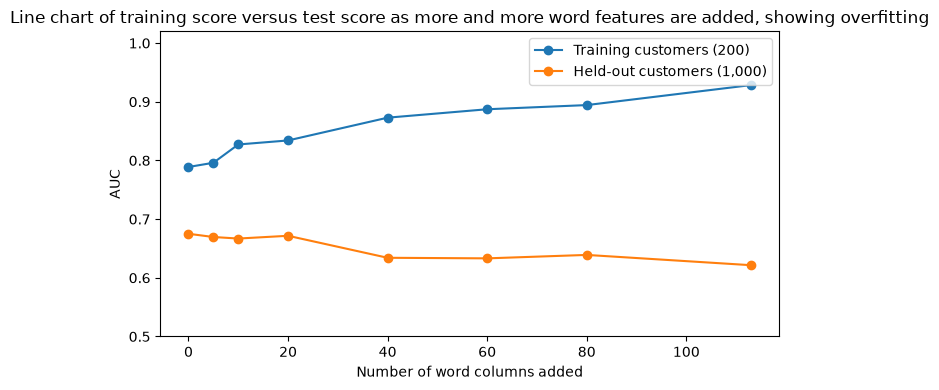

In [9]:
plt.figure(figsize=(7, 4))
plt.plot(sizes, train_scores, marker="o", label="Training customers (200)")
plt.plot(sizes, test_scores, marker="o", label="Held-out customers (1,000)")
plt.xlabel("Number of word columns added")
plt.ylabel("AUC")
plt.ylim(0.5, 1.02)
plt.legend()
plt.title("Line chart of training score versus test score as more and more word features are added, showing overfitting")
plt.tight_layout()
plt.show()

## Step 7: a sanity check on the topic labels
Before trusting any feature, I like to look at it directly. Here is the churn rate for each topic the keyword rule assigned. If bug and billing tickets churn more than praise tickets, the topic label is carrying real signal and not just noise.

In [10]:
churn_by_topic = df.groupby("topic")["churn"].agg(["mean", "size"]).sort_values("mean", ascending=False)
print(churn_by_topic.rename(columns={"mean": "churn rate", "size": "customers"}).round(3))

                 churn rate  customers
topic                                 
bug                   0.402        408
billing               0.309        382
missing feature       0.261        356
how to                0.232        314
praise                0.111        540


## Chart 3: churn rate by topic
The pattern you would hope for in real data: people writing about broken exports and double charges leave much more often than people writing to say thanks. Usage numbers alone could never show you this.

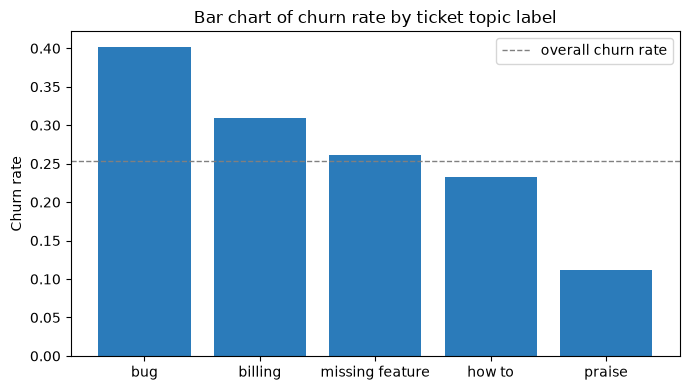

In [11]:
plt.figure(figsize=(7, 4))
plt.bar(churn_by_topic.index, churn_by_topic["mean"], color="#2b7bba")
plt.axhline(df["churn"].mean(), color="grey", linestyle="--", linewidth=1, label="overall churn rate")
plt.ylabel("Churn rate")
plt.legend()
plt.title("Bar chart of churn rate by ticket topic label")
plt.tight_layout()
plt.show()

## What to take away
A handful of meaningful text columns (one sentiment score, a few topic counts) gave a clear lift on customers the model had never seen. Hundreds of raw word columns made the training score shine and the test score worse. Always judge the model on held-out customers, and only use text written before the prediction date. Try it with your own tickets: five topic labels, two models, one test AUC comparison.